# Notebook 4: Sequence Pattern Recognition
**Phase 3, Day 4**

In this notebook: (1) four kinds of synthetic signals, (2) an LSTM/GRU **classifier**, (3) a confusion matrix and the mistakes, (4) visualising hidden states (heatmap and PCA).

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

## Part 1: Synthetic data
Four classes: **sine, square wave, sawtooth, random noise**. Each sequence has a random frequency, phase, amplitude and noise level so the task is not trivial.

In [2]:
CLASSES = ["sine", "square", "sawtooth", "noise"]
T = 100
rng = np.random.default_rng(42)

def make_signal(label, T=T):
    t = np.arange(T)
    cycles = rng.uniform(2, 5)                 # 2 to 5 cycles in 100 steps
    phase = rng.uniform(0, 2 * np.pi)
    amp = rng.uniform(0.8, 1.2)
    arg = 2 * np.pi * cycles * t / T + phase
    if label == 0:   s = np.sin(arg)
    elif label == 1: s = np.sign(np.sin(arg))
    elif label == 2: s = 2 * ((arg / (2 * np.pi)) % 1) - 1
    else:            s = rng.normal(0, 0.6, T)
    s = amp * s + rng.normal(0, rng.uniform(0.1, 0.3), T)   # different noise levels
    return s

n_per_class = 500
X = np.array([make_signal(c) for c in range(4) for _ in range(n_per_class)])
y = np.array([c for c in range(4) for _ in range(n_per_class)])

# Every sequence is independent, so shuffling is fine here
# (for time-series forecasting we split by time instead)
perm = rng.permutation(len(X))
X, y = X[perm], y[perm]

n_tr, n_va = int(0.70 * len(X)), int(0.15 * len(X))
X_train, y_train = X[:n_tr], y[:n_tr]
X_val,   y_val   = X[n_tr:n_tr + n_va], y[n_tr:n_tr + n_va]
X_test,  y_test  = X[n_tr + n_va:], y[n_tr + n_va:]

# Scaling: statistics from the training set
mu, sd = X_train.mean(), X_train.std()
to_t = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32).unsqueeze(-1)   # (N, T, 1)
Xtr, Xva, Xte = to_t(X_train), to_t(X_val), to_t(X_test)
ytr, yva, yte = [torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test)]
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([1400, 100, 1]) torch.Size([300, 100, 1]) torch.Size([300, 100, 1])


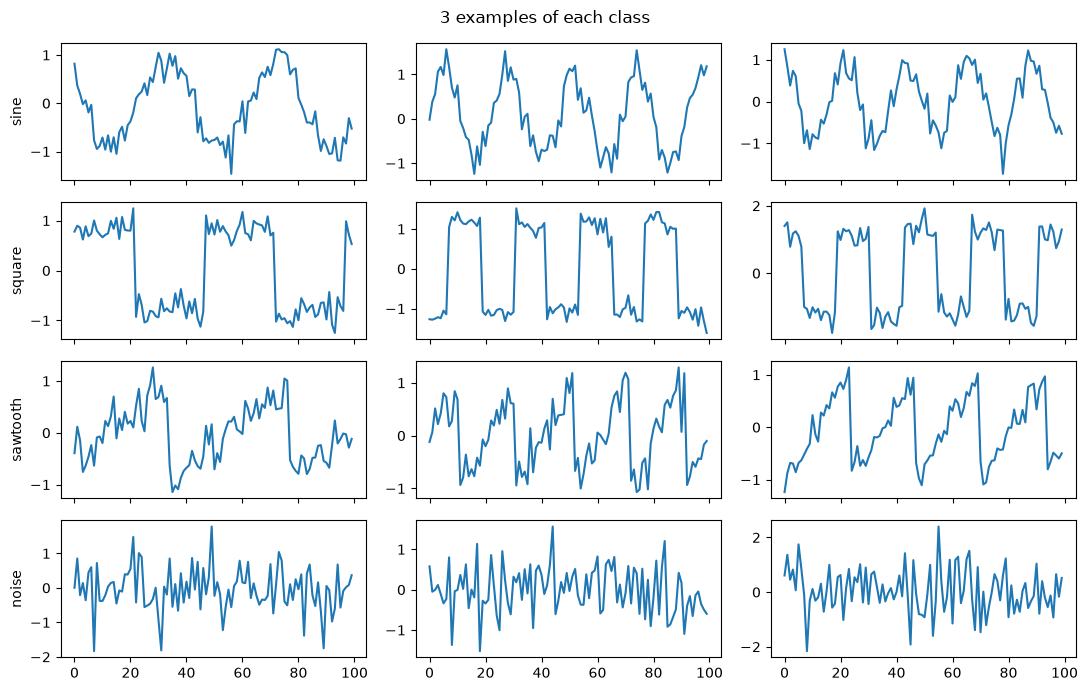

In [3]:
fig, ax = plt.subplots(4, 3, figsize=(11, 7), sharex=True)
for c in range(4):
    idx = np.where(y_train == c)[0][:3]
    for j, i in enumerate(idx):
        ax[c, j].plot(X_train[i])
        if j == 0: ax[c, j].set_ylabel(CLASSES[c])
plt.suptitle("3 examples of each class"); plt.tight_layout(); plt.show()

## Part 2: The classifier
Many-to-one: hidden state of the last time step -> `nn.Linear` -> 4 scores (logits). Loss: **`CrossEntropyLoss`** (for classes; forecasting used MSELoss).

In [4]:
class SeqClassifier(nn.Module):
    def __init__(self, kind="GRU", hidden=32, n_classes=4):
        super().__init__()
        cell = {"LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cell(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x, return_seq=False):
        out, _ = self.rnn(x)                  # out: (B, T, H)
        logits = self.fc(out[:, -1, :])
        return (logits, out) if return_seq else logits

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def train_classifier(kind, epochs=25, bs=64, lr=5e-3):
    torch.manual_seed(0)
    m = SeqClassifier(kind)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lf = nn.CrossEntropyLoss()
    best_acc, best_state, history = 0.0, None, []
    for ep in range(epochs):
        m.train()
        perm = torch.randperm(len(Xtr))
        tot = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = lf(m(Xtr[idx]), ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(idx)
        va = accuracy(m, Xva, yva)
        history.append((tot / len(Xtr), va))
        if va > best_acc:                       # keep the best model on validation
            best_acc, best_state = va, copy.deepcopy(m.state_dict())
        if (ep + 1) % 5 == 0:
            print(f"{kind} epoch {ep+1:2d}  train loss={tot/len(Xtr):.4f}  val acc={va:.3f}")
    m.load_state_dict(best_state)
    return m, history, best_acc

trained = {}
for kind in ("GRU", "LSTM"):
    trained[kind] = train_classifier(kind)
    print()

for kind, (m, hist, va) in trained.items():
    print(f"{kind}: best val acc={va:.3f}")

GRU epoch  5  train loss=0.4464  val acc=0.857
GRU epoch 10  train loss=0.0380  val acc=0.987
GRU epoch 15  train loss=0.0223  val acc=0.993
GRU epoch 20  train loss=0.0067  val acc=1.000
GRU epoch 25  train loss=0.0035  val acc=1.000

LSTM epoch  5  train loss=0.6092  val acc=0.587
LSTM epoch 10  train loss=0.4037  val acc=0.890
LSTM epoch 15  train loss=0.2048  val acc=0.903
LSTM epoch 20  train loss=0.0288  val acc=0.990
LSTM epoch 25  train loss=0.0388  val acc=0.997

GRU: best val acc=1.000
LSTM: best val acc=0.997


Chosen model: GRU
TEST accuracy: 1.000


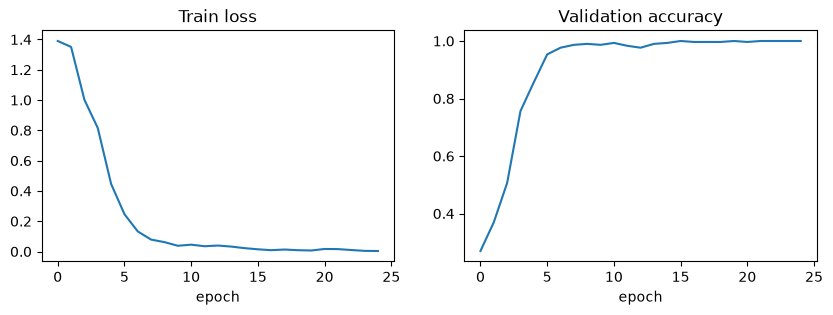

In [5]:
# The better model on validation becomes the final model; the TEST set is used only once
best_kind = max(trained, key=lambda k: trained[k][2])
model = trained[best_kind][0]
print("Chosen model:", best_kind)
print(f"TEST accuracy: {accuracy(model, Xte, yte):.3f}")

hist = np.array(trained[best_kind][1])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist[:, 0]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist[:, 1]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.show()

## Part 3: Confusion matrix and the mistakes

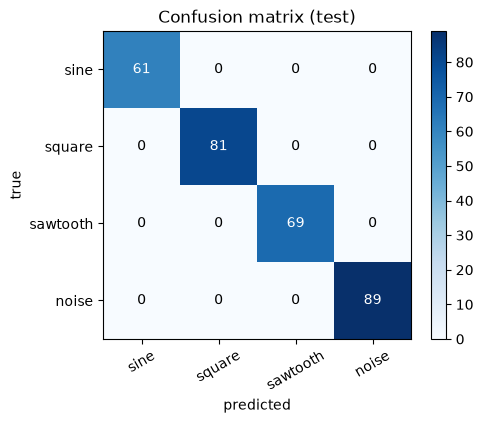

Per-class accuracy:
  sine      1.000
  square    1.000
  sawtooth  1.000
  noise     1.000


In [6]:
model.eval()
with torch.no_grad():
    pred = model(Xte).argmax(1).numpy()
true = yte.numpy()

cm = np.zeros((4, 4), dtype=int)
for t_, p_ in zip(true, pred):
    cm[t_, p_] += 1

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(4), CLASSES, rotation=30); plt.yticks(range(4), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (test)")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(); plt.show()

print("Per-class accuracy:")
for c in range(4):
    print(f"  {CLASSES[c]:9s} {cm[c, c] / cm[c].sum():.3f}")

In [7]:
wrong = np.where(pred != true)[0]
print("Wrong predictions:", len(wrong), "out of", len(true))

show = wrong[:6]
if len(show) == 0:
    print("No mistakes found. Try increasing the noise and run again.")
else:
    fig, ax = plt.subplots(2, 3, figsize=(12, 5))
    for a, i in zip(ax.ravel(), show):
        a.plot(X_test[i])
        a.set_title(f"true: {CLASSES[true[i]]} | pred: {CLASSES[pred[i]]}")
    plt.tight_layout(); plt.show()

Wrong predictions: 0 out of 300
No mistakes found. Try increasing the noise and run again.


**Observation (write in your own words):** which classes were confused with each other (for example sine and square) and why? Look at the misclassified sequences and form an idea.

## Part 4: Visualising hidden states
Let us see what the network has learned inside.

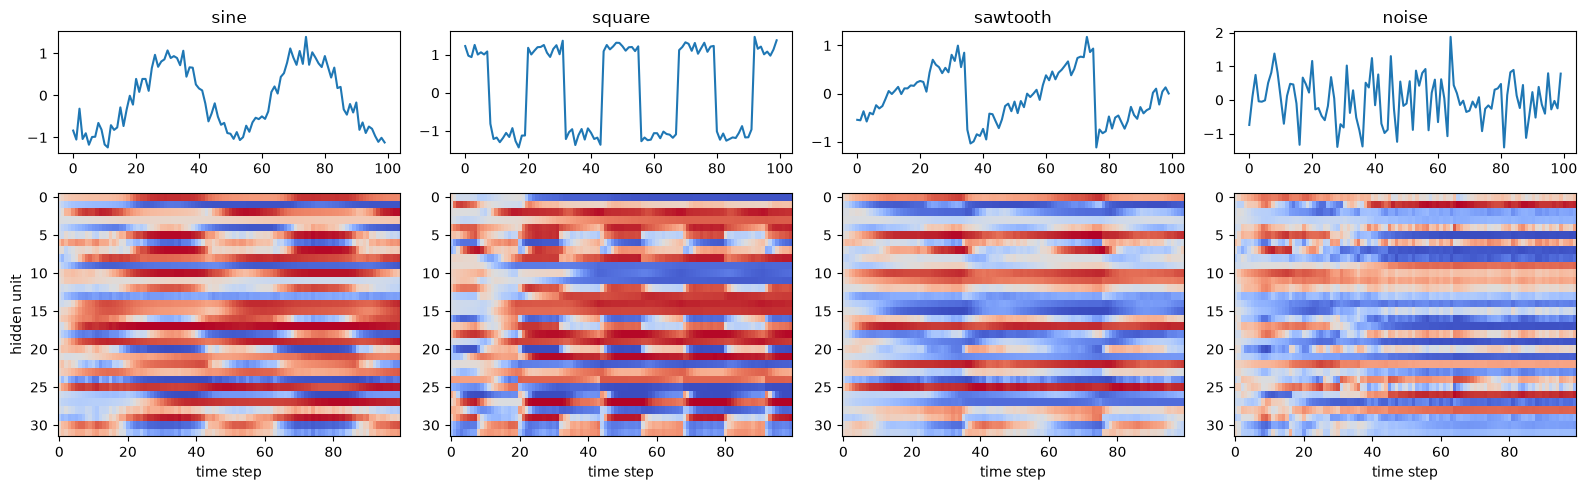

In [8]:
# (a) Heatmap: hidden state over time for one sequence of each class
with torch.no_grad():
    fig, ax = plt.subplots(2, 4, figsize=(16, 5), height_ratios=[1, 2])
    for c in range(4):
        i = np.where(true == c)[0][0]
        _, hs = model(Xte[i:i + 1], return_seq=True)       # (1, T, H)
        ax[0, c].plot(X_test[i]); ax[0, c].set_title(CLASSES[c])
        ax[1, c].imshow(hs[0].T.numpy(), aspect="auto", cmap="coolwarm")
        ax[1, c].set_xlabel("time step")
        if c == 0: ax[1, c].set_ylabel("hidden unit")
plt.tight_layout(); plt.show()

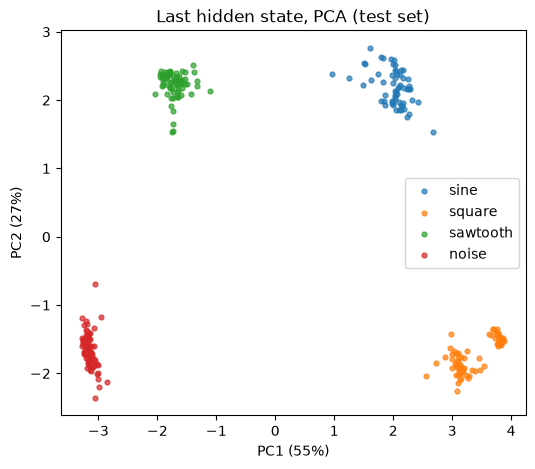

In [9]:
# (b) PCA: reduce the last hidden state (32 dimensions) to 2 dimensions
with torch.no_grad():
    _, hs_all = model(Xte, return_seq=True)
last = hs_all[:, -1, :].numpy()                   # (N, H)

Z = last - last.mean(0)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)  # PCA via SVD
proj = Z @ Vt[:2].T
var = (S ** 2) / np.sum(S ** 2)

plt.figure(figsize=(6, 5))
for c in range(4):
    m_ = true == c
    plt.scatter(proj[m_, 0], proj[m_, 1], s=12, alpha=0.7, label=CLASSES[c])
plt.xlabel(f"PC1 ({var[0]*100:.0f}%)"); plt.ylabel(f"PC2 ({var[1]*100:.0f}%)")
plt.title("Last hidden state, PCA (test set)")
plt.legend(); plt.show()

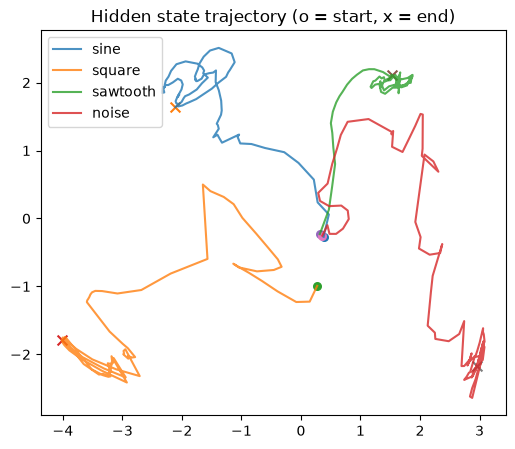

In [10]:
# (c) Hidden-state trajectory of one sequence per class in 2D
Zall = hs_all.numpy().reshape(-1, hs_all.shape[-1])
mean_h = Zall.mean(0)
_, _, Vt2 = np.linalg.svd(Zall - mean_h, full_matrices=False)

plt.figure(figsize=(6, 5))
for c in range(4):
    i = np.where(true == c)[0][0]
    path = (hs_all[i].numpy() - mean_h) @ Vt2[:2].T
    plt.plot(path[:, 0], path[:, 1], alpha=0.8, label=CLASSES[c])
    plt.scatter(path[0, 0], path[0, 1], marker="o", s=30)
    plt.scatter(path[-1, 0], path[-1, 1], marker="x", s=50)
plt.title("Hidden state trajectory (o = start, x = end)")
plt.legend(); plt.show()

**Observation:** do the classes form separate clusters in the PCA plot? Are the classes that were mixed up in the confusion matrix also close together here?

## Summary (write in your own words)
- Output/loss difference between classification and forecasting:
- What the test accuracy and confusion matrix told you:
- What the hidden-state plots showed about the network: